# SpMV on CUDA — Kaggle runner (v2)

**Before running:** right panel → Session options → **Accelerator = GPU T4 x2**, **Internet = On**.

Run the cells **one at a time** (Shift+Enter). Each step prints `STEP OK` or `STEP FAILED` so you can see exactly where a problem is. If one fails, copy its output and send it.

## 0. Helper (run first)

In [1]:
import os, subprocess, glob
os.environ['PATH'] = '/usr/local/cuda/bin:' + os.environ['PATH']
REPO = '/kaggle/working/SpMv'

def run(cmd, cwd=None, tail=40):
    """Run a shell command, show the last `tail` lines, report OK/FAILED."""
    p = subprocess.run(cmd, shell=True, cwd=cwd, text=True,
                       stdout=subprocess.PIPE, stderr=subprocess.STDOUT)
    lines = p.stdout.rstrip().splitlines()
    if len(lines) > tail:
        print(f'... ({len(lines)-tail} earlier lines hidden)')
    print('\n'.join(lines[-tail:]))
    print('\nSTEP OK' if p.returncode == 0 else f'\nSTEP FAILED (exit code {p.returncode})')
    return p.returncode == 0
print('helper ready')

helper ready


## 1. Check GPU and tools

In [2]:
run('nvidia-smi --query-gpu=name,memory.total,driver_version --format=csv')
run('nvcc --version | tail -2')
run('cmake --version | head -1')

name, memory.total [MiB], driver_version
Tesla T4, 15360 MiB, 580.178.04
Tesla T4, 15360 MiB, 580.178.04

STEP OK
Cuda compilation tools, release 12.8, V12.8.93
Build cuda_12.8.r12.8/compiler.35583870_0

STEP OK
cmake version 3.31.10

STEP OK


True

## 2. Clone the repo

In [3]:
run(f'rm -rf {REPO} && git clone https://github.com/bettercallok/SpMv.git {REPO}')
os.chdir(REPO); print('cwd:', os.getcwd())

Cloning into '/kaggle/working/SpMv'...

STEP OK
cwd: /kaggle/working/SpMv


## 3. Build (T4 = architecture 75)

In [4]:
ok = run('cmake -S . -B build -DCMAKE_BUILD_TYPE=Release '
         '-DCMAKE_CUDA_ARCHITECTURES=75 -DCMAKE_CUDA_COMPILER=/usr/local/cuda/bin/nvcc', cwd=REPO, tail=15)
ok = ok and run('cmake --build build -j4', cwd=REPO, tail=30)
print('spmv_bench exists:', os.path.exists(f'{REPO}/build/spmv_bench'))

... (4 earlier lines hidden)
-- Detecting CXX compile features
-- Detecting CXX compile features - done
-- The CUDA compiler identification is NVIDIA 12.8.93 with host compiler GNU 13.3.0
-- Detecting CUDA compiler ABI info
-- Detecting CUDA compiler ABI info - done
-- Check for working CUDA compiler: /usr/local/cuda/bin/nvcc - skipped
-- Detecting CUDA compile features
-- Detecting CUDA compile features - done
-- Found CUDAToolkit: /usr/local/cuda/targets/x86_64-linux/include (found version "12.8.93")
-- Performing Test CMAKE_HAVE_LIBC_PTHREAD
-- Performing Test CMAKE_HAVE_LIBC_PTHREAD - Success
-- Found Threads: TRUE
-- Configuring done (4.9s)
-- Generating done (0.0s)
-- Build files have been written to: /kaggle/working/SpMv/build

STEP OK
[  7%] Building CXX object CMakeFiles/spmv_host.dir/src/mmio.cpp.o
[ 15%] Building CXX object CMakeFiles/spmv_host.dir/src/convert.cpp.o
[ 23%] Building CXX object CMakeFiles/spmv_host.dir/src/generate.cpp.o
[ 30%] Building CXX object CMakeFiles/s

## 4. CPU tests

In [5]:
run('ctest --output-on-failure', cwd=f'{REPO}/build', tail=15)

Test project /kaggle/working/SpMv/build
    Start 1: test_cpu
1/1 Test #1: test_cpu .........................   Passed    0.00 sec

100% tests passed, 0 tests failed out of 1

Total Test time (real) =   0.02 sec

STEP OK


True

## 5. Quick GPU check on synthetic matrices — every kernel should say `ok`

In [6]:
run('./build/spmv_bench --peak-bw 320 --csv "" laplace2d:1000 random:1000000:16', cwd=REPO)

GPU: Tesla T4 (sm_75), CUDA runtime 12080, peak DRAM 320.0 GB/s; 5 warm-ups + median of 100 launches

laplace2d_1000: 1000000 x 1000000, nnz 4996000, row length mean 5.0 max 5, ELL padding 1.0x, HYB k=5 (0% in COO)
  kernel           status   median ms  GFLOP/s     GB/s   %peak  vs cuSP  conv ms  max err
  cusparse         ok          0.3151    31.71    164.9   51.5%    1.00x     52.9  1.9e-07 
  csr_scalar       ok          0.2195    45.53    236.8   74.0%    1.44x      0.0  1.8e-07 
  csr_vector       ok          1.4910     6.70     34.9   10.9%    0.21x      0.0  1.2e-07 
  csr_vector_auto  ok          0.3336    29.96    155.8   48.7%    0.94x      0.0  1.2e-07 width=8
  ell              ok          0.2119    47.16    226.6   70.8%    1.49x     36.0  1.8e-07 
  coo              ok          0.3154    31.68    215.4   67.3%    1.00x     43.4  1.9e-07 
  hyb              ok          0.2130    46.91    225.4   70.4%    1.48x     18.1  1.8e-07 k=5

random_1000000_16: 1000000 x 1000000, n

True

## 6. Download SuiteSparse matrices (~5–10 min)
If this fails, you can still continue — step 7 falls back to the synthetic matrices.

In [10]:
import io, tarfile, requests, numpy as np, pandas as pd
HF = 'https://huggingface.co/datasets/Csed-dev/matrixpfn-suitesparse/resolve/main'
MDIR = f'{REPO}/matrices'; os.makedirs(MDIR, exist_ok=True)

# 1) Read the catalogue and pick 9 large matrices with different average row lengths
man = pd.read_parquet(io.BytesIO(requests.get(f'{HF}/manifest.parquet', timeout=60).content))
cols = {c.lower(): c for c in man.columns}
def col(*names):
    for n in names:
        for k, c in cols.items():
            if n in k: return c
    raise KeyError(f'none of {names} in {list(man.columns)}')
c_name, c_rows, c_nnz = col('name'), col('row', 'n_rows', 'm'), col('nnz', 'nonzero')
dom = next((cols[k] for k in cols if 'domain' in k or 'kind' in k), None)
man['mean_row'] = man[c_nnz] / man[c_rows]
big = man[man[c_nnz] >= 500_000].copy()                 # large enough to measure bandwidth
big['bucket'] = pd.qcut(big.mean_row.rank(method='first'), 9, labels=False)
pick = big.sort_values(c_nnz, ascending=False).groupby('bucket').head(1).sort_values('mean_row')
show = [c_name, c_rows, c_nnz, 'mean_row'] + ([dom] if dom else [])
print(pick[show].round(1).to_string(index=False))
want = set(pick[c_name].astype(str))

# 2) Stream the archive and keep only the chosen .mtx files (no 5.7 GB extract)
have = {os.path.basename(p)[:-4] for p in glob.glob(f'{MDIR}/*.mtx')}
todo = want - have
if todo:
    with requests.get(f'{HF}/suitesparse.tar.gz', stream=True, timeout=120) as r:
        r.raise_for_status(); r.raw.decode_content = True
        with tarfile.open(fileobj=r.raw, mode='r|gz') as tar:
            for m in tar:
                base = os.path.basename(m.name)
                if m.isfile() and base.endswith('.mtx') and base[:-4] in todo:
                    with open(f'{MDIR}/{base}', 'wb') as f:
                        shutil.copyfileobj(tar.extractfile(m), f)
                    todo.discard(base[:-4]); print('got', base, f'({len(todo)} left)')
                    if not todo: break
print('missing:', todo or 'none')

# 3) Synthetic power-law matrix (web-graph shape, 1M rows) - the worst case for ELL
pl = f'{MDIR}/powerlaw_1M.mtx'
if not os.path.exists(pl):
    rng = np.random.default_rng(7); n = 1_000_000
    lens = np.minimum(np.floor(rng.pareto(1.6, n) + 1).astype(np.int64) * 2, 5000)
    rows = np.repeat(np.arange(1, n + 1), lens)
    cols_ = rng.integers(1, n + 1, rows.size); vals = rng.uniform(-1, 1, rows.size)
    with open(pl, 'w') as f:
        f.write(f'%%MatrixMarket matrix coordinate real general\n{n} {n} {rows.size}\n')
        np.savetxt(f, np.column_stack([rows, cols_, vals]), fmt='%d %d %.6f')
    print(f'powerlaw_1M: nnz={rows.size:,}, mean row={lens.mean():.1f}, max row={lens.max()}')

mats = sorted(glob.glob(f'{MDIR}/*.mtx'))
print(len(mats), 'matrices:', [os.path.basename(m) for m in mats])

            name   rows     nnz  mean_row                                 kind
  uni_chimera_i4 100000  814436       8.1            undirected weighted graph
       ASIC_100k  99340  940621       9.5           circuit simulation problem
           boyd1  93279 1211231      13.0                 optimization problem
           qa8fk  66127 1660579      25.1                    acoustics problem
TSOPF_FS_b39_c19  76216 1977600      25.9                power network problem
     Goodwin_071  56021 1797934      32.1         computational fluid dynamics
     mixtank_new  29957 1990919      66.5 computational fluid dynamics problem
         Zd_Jac3  22835 1915726      83.9  chemical process simulation problem
            appu  14000 1853104     132.4       directed weighted random graph
got appu.mtx (8 left)
got boyd1.mtx (7 left)
got TSOPF_FS_b39_c19.mtx (6 left)
got qa8fk.mtx (5 left)
got mixtank_new.mtx (4 left)
got Zd_Jac3.mtx (3 left)
got uni_chimera_i4.mtx (2 left)
got ASIC_100k.mtx (1 l

## 7. Matrix stats + full benchmark (~5–15 min)

In [11]:
os.makedirs(f'{REPO}/results', exist_ok=True)
mats = sorted(glob.glob(f'{REPO}/matrices/*.mtx'))
if mats:
    run('python3 scripts/matrix_stats.py matrices/*.mtx > results/matrix_stats.md && cat results/matrix_stats.md', cwd=REPO)
else:
    print('No .mtx files found - benchmarking synthetic matrices only.')
if os.path.exists(f'{REPO}/results/results.csv'):
    os.remove(f'{REPO}/results/results.csv')
targets = ' '.join(['matrices/*.mtx'] if mats else []) + ' laplace2d:1000 random:1000000:16'
run(f'./build/spmv_bench --peak-bw 320 --csv results/results.csv {targets} 2>&1 | tee results/bench_log.txt',
    cwd=REPO, tail=80)

| matrix | rows | nnz | mean/row | max/row | ELL padding | HYB k | HYB COO % |
|---|---|---|---|---|---|---|---|
| ASIC_100k | 99340 | 954163 | 9.6 | 99029 | 10310.1 | 8 | 28.4 |
| Goodwin_071 | 56021 | 1797934 | 32.1 | 62 | 1.9 | 36 | 14.2 |
| TSOPF_FS_b39_c19 | 76216 | 1977600 | 25.9 | 38024 | 1465.4 | 33 | 28.8 |
| Zd_Jac3 | 22835 | 1916152 | 83.9 | 1050 | 12.5 | 20 | 90.2 |
| appu | 14000 | 1853104 | 132.4 | 294 | 2.2 | 144 | 7.2 |
| boyd1 | 93279 | 1211231 | 13.0 | 93261 | 7182.2 | 7 | 49.0 |
| mixtank_new | 29957 | 1995041 | 66.6 | 154 | 2.3 | 94 | 11.3 |
| powerlaw_1M | 1000000 | 4513924 | 4.5 | 5000 | 1107.7 | 2 | 55.7 |
| qa8fk | 66127 | 1660579 | 25.1 | 27 | 1.1 | 27 | 0.0 |
| uni_chimera_i4 | 100000 | 814436 | 8.1 | 18 | 2.2 | 9 | 5.3 |

STEP OK
... (41 earlier lines hidden)

appu: 14000 x 14000, nnz 1853104, row length mean 132.4 max 294, ELL padding 2.2x, HYB k=144 (7% in COO)
  kernel           status   median ms  GFLOP/s     GB/s   %peak  vs cuSP  conv ms  max err
  cusp

True

## 8. Charts

In [16]:
run('python3 scripts/plot.py results/results.csv results', cwd=REPO)

wrote results/gbps.png and results/roofline.png

STEP OK


True

## 9. Show results

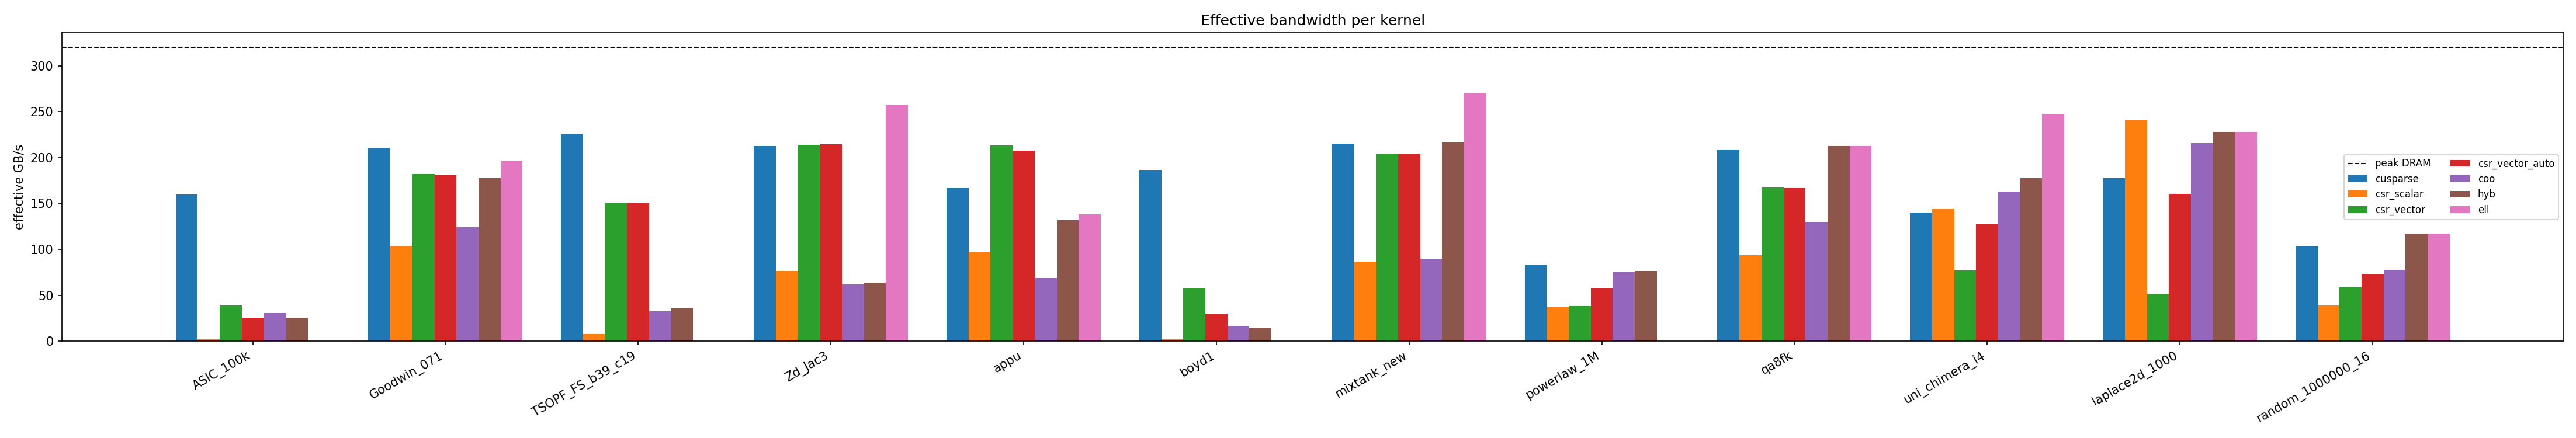

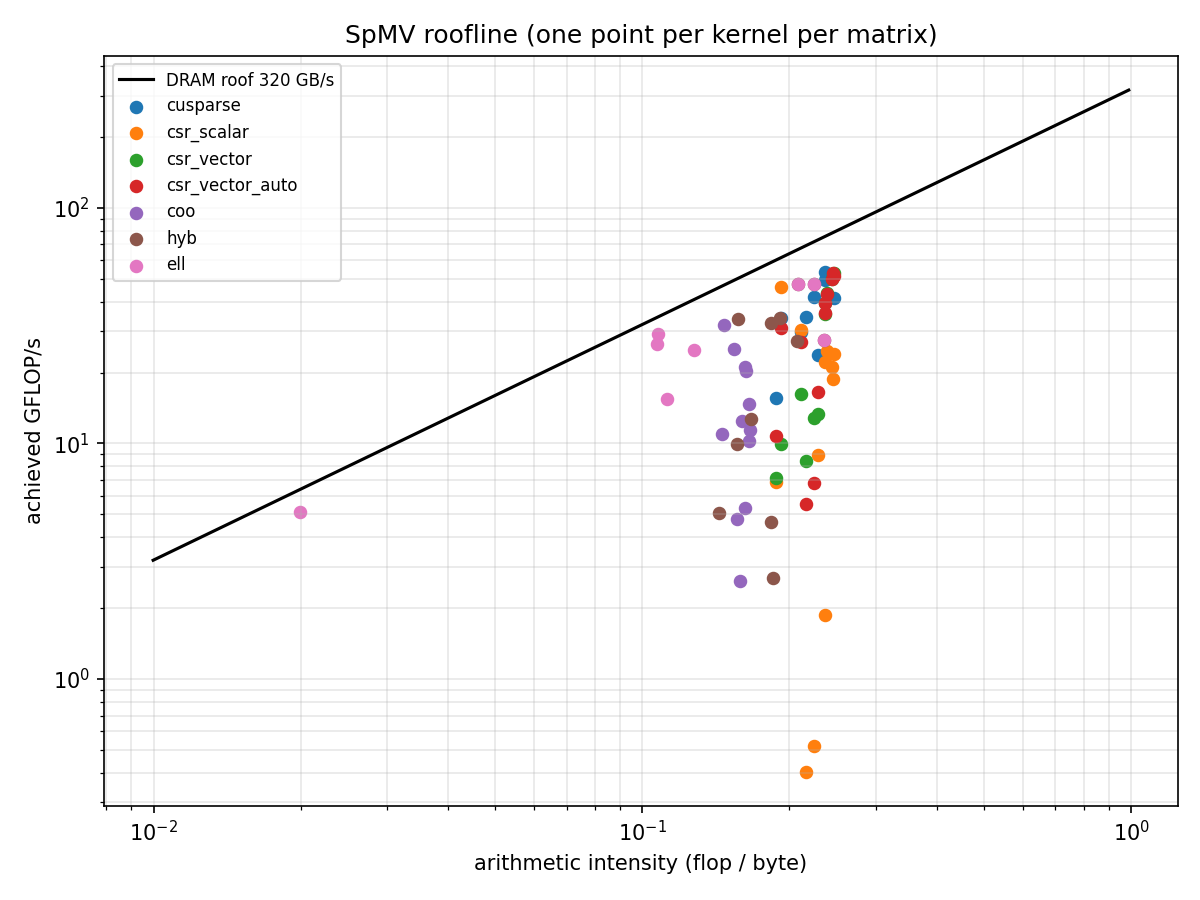

status
ok         80
skipped     4 

Best % of peak bandwidth: 84.5

Best speedup vs cuSPARSE per matrix:
matrix
ASIC_100k            0.24
Goodwin_071          0.86
TSOPF_FS_b39_c19     0.67
Zd_Jac3              1.01
appu                 1.28
boyd1                0.31
laplace2d_1000       1.39
mixtank_new          0.95
powerlaw_1M          0.82
qa8fk                0.97
random_1000000_16    1.16
uni_chimera_i4       1.15


,matrix,kernel,median_ms,gbps,pct_peak,speedup_vs_cusparse,note
0,ASIC_100k,cusparse,0.055280,159.6490,49.89030,1.000000,NaN
2,ASIC_100k,csr_vector,0.226288,39.0007,12.18770,0.244290,NaN
5,ASIC_100k,coo,0.399312,30.6644,9.58264,0.138438,NaN
3,ASIC_100k,csr_vector_auto,0.344368,25.6278,8.00868,0.160526,width=16
6,ASIC_100k,hyb,0.411904,25.2582,7.89319,0.134206,k=8
...,...,...,...,...,...,...,...
68,uni_chimera_i4,coo,0.064896,162.9260,50.91430,0.847387,NaN
64,uni_chimera_i4,csr_scalar,0.053520,144.1610,45.05030,1.027500,NaN
63,uni_chimera_i4,cusparse,0.054992,140.3020,43.84440,1.000000,NaN
66,uni_chimera_i4,csr_vector_auto,0.060512,127.5040,39.84480,0.908778,width=16


In [17]:
from IPython.display import Image, display
import pandas as pd
for f in ['gbps.png', 'roofline.png']:
    p = f'{REPO}/results/{f}'
    display(Image(p)) if os.path.exists(p) else print('missing', p, '- check step 8')
csv = f'{REPO}/results/results.csv'
if os.path.exists(csv):
    df = pd.read_csv(csv)
    print(df.status.value_counts().to_string(), '\n')
    ok = df[df.status == 'ok']
    mine = ok[ok.kernel != 'cusparse']
    if len(mine):
        print('Best % of peak bandwidth:', round(mine.pct_peak.max(), 1))
        print('\nBest speedup vs cuSPARSE per matrix:')
        print(mine.groupby('matrix').speedup_vs_cusparse.max().round(2).to_string())
    display(ok.sort_values(['matrix', 'gbps'], ascending=[True, False])[
        ['matrix', 'kernel', 'median_ms', 'gbps', 'pct_peak', 'speedup_vs_cusparse', 'note']])
else:
    print('No results.csv - check step 7 output.')

## 10. Optional: `__ldg` build for before/after comparison

In [18]:
if run('cmake -S . -B build_ldg -DCMAKE_CUDA_ARCHITECTURES=75 -DSPMV_USE_LDG=ON '
       '-DCMAKE_CUDA_COMPILER=/usr/local/cuda/bin/nvcc && cmake --build build_ldg -j4', cwd=REPO, tail=10):
    t = 'matrices/*.mtx' if glob.glob(f'{REPO}/matrices/*.mtx') else ''
    run(f'./build_ldg/spmv_bench --peak-bw 320 --csv results/results_ldg.csv {t} laplace2d:1000 random:1000000:16',
        cwd=REPO, tail=60)

... (25 earlier lines hidden)
[ 46%] Building CXX object CMakeFiles/test_cpu.dir/tests/test_cpu.cpp.o
[ 53%] Building CUDA object CMakeFiles/spmv_bench.dir/src/spmv_csr.cu.o
[ 69%] Building CUDA object CMakeFiles/spmv_bench.dir/src/spmv_coo.cu.o
[ 69%] Building CUDA object CMakeFiles/spmv_bench.dir/src/spmv_ell.cu.o
[ 76%] Linking CXX executable test_cpu
[ 76%] Built target test_cpu
[ 84%] Building CUDA object CMakeFiles/spmv_bench.dir/src/spmv_hyb.cu.o
[ 92%] Building CUDA object CMakeFiles/spmv_bench.dir/src/bench.cu.o
[100%] Linking CXX executable spmv_bench
[100%] Built target spmv_bench

STEP OK
... (61 earlier lines hidden)

mixtank_new: 29957 x 29957, nnz 1995041, row length mean 66.6 max 154, ELL padding 2.3x, HYB k=94 (11% in COO)
  kernel           status   median ms  GFLOP/s     GB/s   %peak  vs cuSP  conv ms  max err
  cusparse         ok          0.0760    52.52    214.8   67.1%    1.00x      1.2  1.8e-07 
  csr_scalar       ok          0.2970    13.44     55.0   17.2%    

## 11. Optional: Nsight Compute (usually blocked on Kaggle)

In [22]:
if run('ncu --version'):
    run('bash scripts/profile.sh', cwd=REPO, tail=30)
else:
    print('ncu not available here - do profiling on a lab GPU.')

NVIDIA (R) Nsight Compute Command Line Profiler
Copyright (c) 2018-2025 NVIDIA Corporation
Version 2025.1.1.0 (build 35528883) (public-release)

STEP OK
... (19 earlier lines hidden)
error on /kaggle/working/SpMv/matrices/webbase-1M.mtx: cannot open /kaggle/working/SpMv/matrices/webbase-1M.mtx
   ncu failed for webbase-1M / csr_scalar
== webbase-1M / csr_vector
error on /kaggle/working/SpMv/matrices/webbase-1M.mtx: cannot open /kaggle/working/SpMv/matrices/webbase-1M.mtx
   ncu failed for webbase-1M / csr_vector
== webbase-1M / ell
error on /kaggle/working/SpMv/matrices/webbase-1M.mtx: cannot open /kaggle/working/SpMv/matrices/webbase-1M.mtx
   ncu failed for webbase-1M / ell
== webbase-1M / coo
error on /kaggle/working/SpMv/matrices/webbase-1M.mtx: cannot open /kaggle/working/SpMv/matrices/webbase-1M.mtx
   ncu failed for webbase-1M / coo
== webbase-1M / hyb
error on /kaggle/working/SpMv/matrices/webbase-1M.mtx: cannot open /kaggle/working/SpMv/matrices/webbase-1M.mtx
   ncu failed fo

## 12. Save results → download `results.zip` from the Output panel (right side)

In [24]:
if os.path.isdir(f'{REPO}/results') and os.listdir(f'{REPO}/results'):
    run(f'cd {REPO} && zip -qr /kaggle/working/results.zip results && ls -lh /kaggle/working/results.zip')
    print(os.listdir(f'{REPO}/results'))
else:
    print('results/ is empty - nothing to save yet. Fix the failing step above first.')

-rw-r--r-- 1 root root 179K Oct 25 10:24 /kaggle/working/results.zip

STEP OK
['results.csv', 'bench_log.txt', 'ncu', 'roofline.png', 'results_ldg.csv', 'gbps.png', 'matrix_stats.md']
